In [ ]:
import zipfile
import urllib.request
import os

# URL of the dataset from UCI Machine Learning Repository
url = 'https://archive.ics.uci.edu/static/public/320/student+performance.zip'
zip_path = '/content/student_performance.zip'

# Download the file if it does not exist
if not os.path.exists(zip_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download complete.")

# Extract the dataset
print("Extracting dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/student_data')

print("Dataset extracted successfully to /content/student_data!")

Download complete.
Extracting dataset...
Dataset extracted successfully to /content/student_data!


In [ ]:
import zipfile
import os

nested_zip_path = '/content/student_data/student.zip'
extract_dir = '/content/student_data'

if os.path.exists(nested_zip_path):
    print("Extracting nested student.zip...")
    with zipfile.ZipFile(nested_zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Nested zip extracted successfully!")
    print("Files in extraction directory:", os.listdir(extract_dir))
else:
    print(f"Could not find nested zip at {nested_zip_path}")

Extracting nested student.zip...
Nested zip extracted successfully!
Files in extraction directory: ['student-por.csv', 'student.zip', 'student.txt', '.student.zip_old', 'student-mat.csv', 'student-merge.R']


In [ ]:
import pandas as pd

# Load the mathematics student performance dataset
file_path = '/content/student_data/student-mat.csv'
df_mat = pd.read_csv(file_path, sep=';')

# Display the first few rows
display(df_mat.head())

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
import pandas as pd

# Check dataset size
print("Dataset Shape:", df_mat.shape)

# Check column names and data types
print("\nDataset Information:")
df_mat.info()

# Check missing values
print("\nMissing Values:")
print(df_mat.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df_mat.duplicated().sum())

# Check target variable
print("\nFinal Grade (G3) Details:")
print(df_mat['G3'].describe())

Dataset Shape: (395, 33)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nur

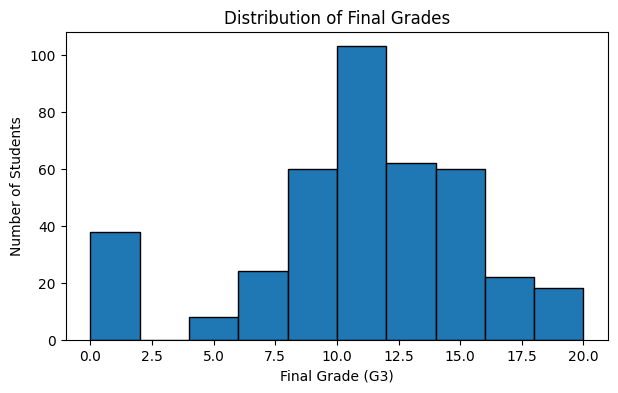

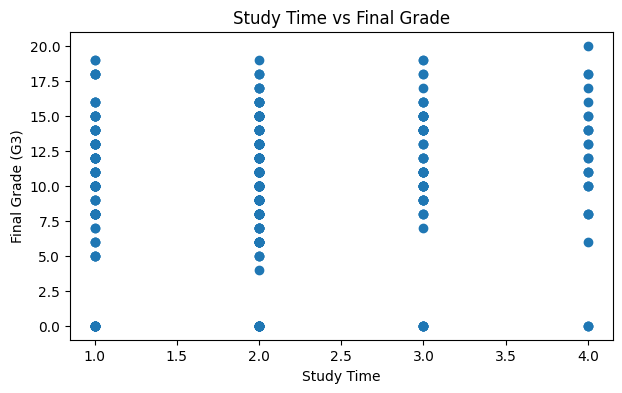

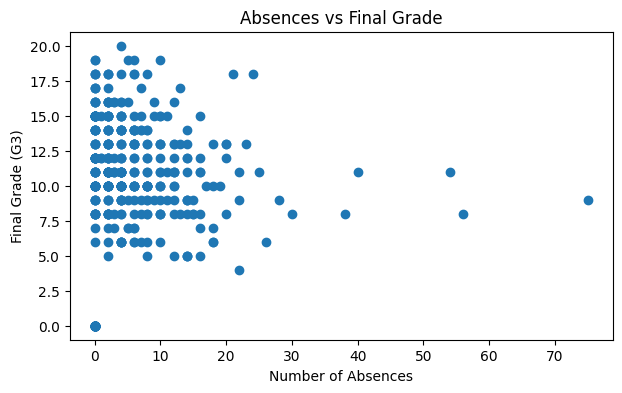

In [ ]:
import matplotlib.pyplot as plt

# Graph 1: Distribution of Final Grades (G3)
plt.figure(figsize=(7, 4))
plt.hist(df_mat['G3'], bins=10, edgecolor='black')
plt.title('Distribution of Final Grades')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')
plt.show()


# Graph 2: Study Time vs Final Grade
plt.figure(figsize=(7, 4))
plt.scatter(df_mat['studytime'], df_mat['G3'])
plt.title('Study Time vs Final Grade')
plt.xlabel('Study Time')
plt.ylabel('Final Grade (G3)')
plt.show()


# Graph 3: Absences vs Final Grade
plt.figure(figsize=(7, 4))
plt.scatter(df_mat['absences'], df_mat['G3'])
plt.title('Absences vs Final Grade')
plt.xlabel('Number of Absences')
plt.ylabel('Final Grade (G3)')
plt.show()

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare dataset
df = df_mat.copy()

X = df.drop('G3', axis=1)
y = df['G3']

# Convert categorical data into numerical data
X = pd.get_dummies(X, drop_first=True)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create models
lr_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train models
lr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# Make predictions
lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Evaluate models
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    'MSE': [
        mean_squared_error(y_test, lr_pred),
        mean_squared_error(y_test, rf_pred)
    ],
    'RMSE': [
        mean_squared_error(y_test, lr_pred) ** 0.5,
        mean_squared_error(y_test, rf_pred) ** 0.5
    ],
    'R2 Score': [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ]
})

print("Model Training and Testing Completed!")
display(results.round(3))

Model Training and Testing Completed!


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.647,5.657,2.378,0.724
1,Random Forest,1.165,3.798,1.949,0.815


In [ ]:
# Display model comparison
print("MODEL COMPARISON RESULTS")
display(results.round(3))

MODEL COMPARISON RESULTS


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.647,5.657,2.378,0.724
1,Random Forest,1.165,3.798,1.949,0.815


In [ ]:
# Compare actual and predicted grades
comparison = pd.DataFrame({
    'Actual Grade': y_test.values,
    'Linear Regression Prediction': lr_pred.round(2),
    'Random Forest Prediction': rf_pred.round(2)
})

print("ACTUAL VS PREDICTED GRADES")
display(comparison.head(10))

ACTUAL VS PREDICTED GRADES


,Actual Grade,Linear Regression Prediction,Random Forest Prediction
0,10,6.00,8.32
1,12,11.53,11.78
2,5,2.87,6.50
3,10,8.80,9.76
4,9,8.55,8.80
5,13,11.89,12.86
6,18,19.10,18.70
7,6,7.17,6.72
8,0,7.41,6.68
9,14,12.31,13.33


In [ ]:
# Predict the grade of one test student
sample_student = X_test.iloc[[0]]

lr_grade = lr_model.predict(sample_student)[0]
rf_grade = rf_model.predict(sample_student)[0]

print("Actual Grade:", y_test.iloc[0])
print("Linear Regression Predicted Grade:", round(lr_grade, 2))
print("Random Forest Predicted Grade:", round(rf_grade, 2))

Actual Grade: 10
Linear Regression Predicted Grade: 6.0
Random Forest Predicted Grade: 8.32
